## Module 3: Computational Drug Discovery Project 



## Disease Background

- Obesity is a medical condition defined by a BMI of 30 or higher․ Approximately 40․3% of U․S․ adults reported being obese in 2021-2023‚ according to CDC data․ Health complications related to obesity include type 2 diabetes‚ heart disease‚ and high blood pressure․ [CDC Data](https://www.cdc.gov/nchs/products/databriefs/db508.htm)

- Obesity treatments include behavioral therapy and weight-loss drugs and surgery․ New weight-loss drugs include Wegovy (semaglutide) and Zepbound (tirzepatide)․ Weight-loss drugs work by affecting hormone pathways involved in appetite control․ [Obesity Treatments](https://www.niddk.nih.gov/health-information/weight-management/adult-overweight-obesity/treatment) | [Weight-Loss Medications](https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity)

- Current therapies have limitations․ Medications may have side effects and need to be used for many years‚ among other limitations‚ and may not be covered or fully reimbursed by most insurance and other payers․ Ways to overcome barriers to therapy include the development of more convenient and inexpensive treatments․ [Medication Limitations](https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity)

- Our project focuses on Cavalitide‚ a proposed GLP1 receptor agonist․ We are studying Cavalitide receptor binding and concentration over time to gain knowledge that could help make Cavalitide a useful alternative to other weight-loss medications․ (Module 3 Project Description)


## Task 1: Fit a receptor binding model for Cavalitide:


In [10]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Load Cavalitide experimental data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)

print("Data loaded successfully!")
print(data[:5])


Data loaded successfully!
[[0.001      0.09528827]
 [0.00284804 0.10622711]
 [0.00811131 0.17861281]
 [0.0231013  0.27693139]
 [0.06579332 0.46054832]]


Cavalitide Kd: 0.07696604138418876 nM


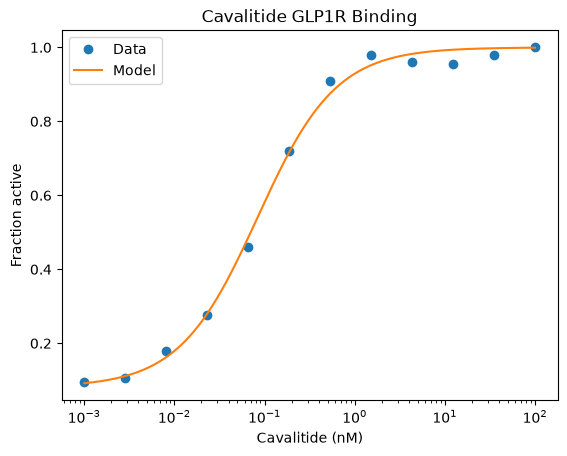

In [11]:

# Cavalitide data
L2 = data[:, 0]
y = data[:, 1]

# GLP1 values
L1 = 0.015
Kd1 = 0.17

# Receptor activation
def Fact(L2, Kd2):
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Finding Kd for Cavalitide
popt, pcov = curve_fit(Fact, L2, y, p0=[0.1])
Kd2 = popt[0]

print("Cavalitide Kd:", Kd2, "nM")

# Plot
x = np.logspace(-3, 2, 500)

plt.figure()
plt.semilogx(L2, y, 'o', label="Data")
plt.semilogx(x, Fact(x, Kd2), label="Model")

plt.xlabel("Cavalitide (nM)")
plt.ylabel("Fraction active")
plt.title("Cavalitide GLP1R Binding")
plt.legend()
plt.show()


### Task 1 Interpretation

The Kd value for Cavalitide is 0․077 nM‚ and the Kd value for semaglutide is 0․38 nM․ Cavalitide has a lower Kd value and may have increased receptor binding and activation of GLP1R at lower concentrations․ Other factors‚ in addition to receptor binding and activation‚ such as absorption and half-life‚ should be taken into account when comparing potential drugs․ Stronger binding alone does not indicate increased weight loss or safety.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment


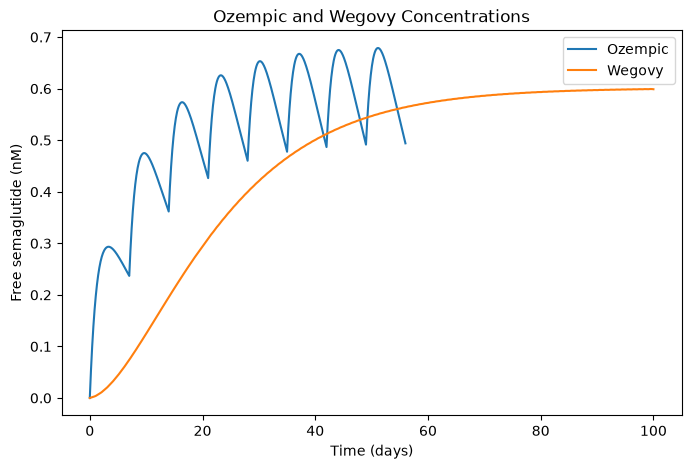

In [12]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Values from semaglutidePK.py
ke = 0.0039
V = 10.8
MW = 4113.6
Ffree = 0.01

def ODEfunc(t, y, ka):
    Asc, Cc = y
    dAsc = -ka * Asc
    dCc = ka * Asc / V - ke * Cc
    return [dAsc, dCc]

def simulate(ka, D, Favailable, interval, n_doses):
    y = [0, 0]
    times = []
    concentrations = []

    for i in range(n_doses):
        y[0] += Favailable * D
        t0 = i * interval

        sol = solve_ivp(
            ODEfunc, [t0, t0 + interval], y,
            args=(ka,),
            t_eval=np.linspace(t0, t0 + interval, 100)
        )

        times.extend(sol.t)
        concentrations.extend(sol.y[1])
        y = sol.y[:, -1].copy()

    times = np.array(times)
    concentrations = np.array(concentrations)

    CnM = concentrations * 1e6 / MW
    return times, Ffree * CnM

# Ozempic
t1, c1 = simulate(0.029, 2.0, 0.89, 168, 8)

# Wegovy
t2, c2 = simulate(0.0029, 25, 0.01, 24, 100)

plt.figure(figsize=(8, 5))
plt.plot(t1/24, c1, label="Ozempic")
plt.plot(t2/24, c2, label="Wegovy")
plt.xlabel("Time (days)")
plt.ylabel("Free semaglutide (nM)")
plt.title("Ozempic and Wegovy Concentrations")
plt.legend()
plt.show()


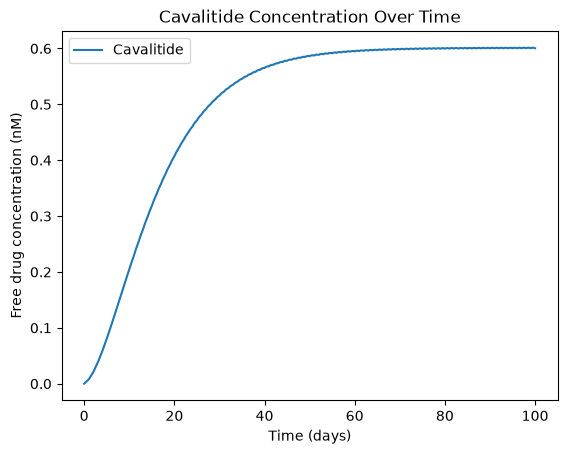

Cavalitide concentration at day 100: 0.600383837692971 nM


In [13]:

# Cavalitide with a faster absorption rate
t3, c3 = simulate(0.006, 25, 0.01, 24, 100)

plt.figure()
plt.plot(t3/24, c3, label="Cavalitide")
plt.xlabel("Time (days)")
plt.ylabel("Free drug concentration (nM)")
plt.title("Cavalitide Concentration Over Time")
plt.legend()
plt.show()

print("Cavalitide concentration at day 100:", c3[-1], "nM")


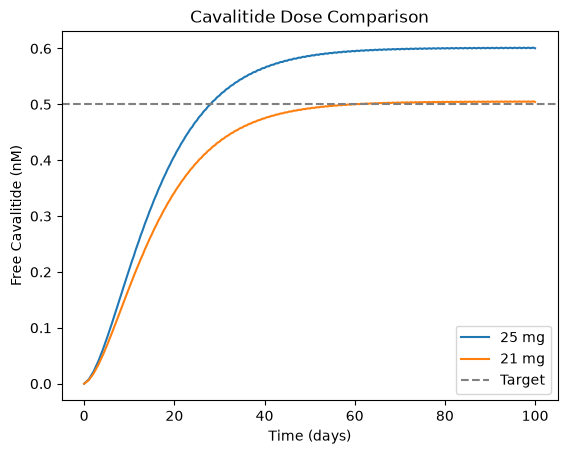

Concentration with 21 mg: 0.5043224236622355 nM


In [14]:

# Trying a lower daily dose for Cavalitide
t4, c4 = simulate(0.006, 21, 0.01, 24, 100)

plt.figure()
plt.plot(t3/24, c3, label="25 mg")
plt.plot(t4/24, c4, label="21 mg")
plt.axhline(0.5, color="gray", linestyle="--", label="Target")

plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide (nM)")
plt.title("Cavalitide Dose Comparison")
plt.legend()
plt.show()

print("Concentration with 21 mg:", c4[-1], "nM")


### Task 2 Interpretation

I reduced the daily Cavalitide dose from 25 mg to 21 mg while keeping the other parameters the same. This decreased the steady-state free blood concentration from about 0.60 nM to 0.50 nM, which is closer to our target.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment



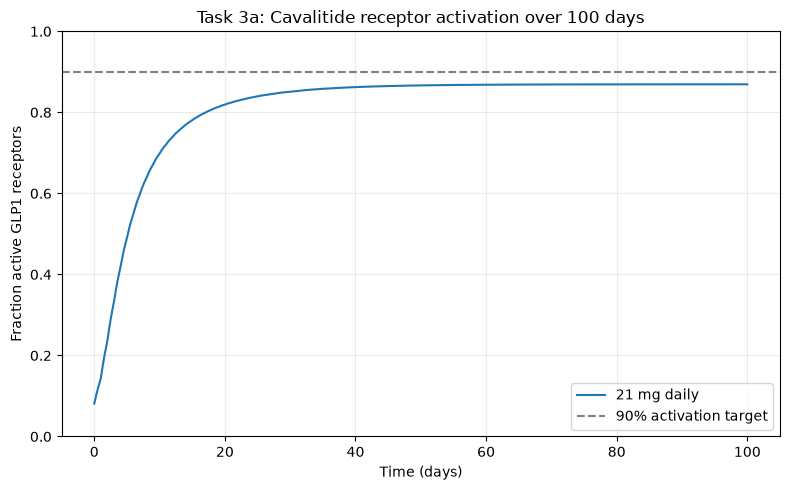

Cavalitide Kd: 0.07697 nM
Free concentration at day 100: 0.5043 nM
Activation at day 100: 86.91%
Average activation during final day: 86.92%


In [15]:
#Code for question 1
from scipy.integrate import trapezoid

# Keep the fitted binding constant from Task 1 fixed.
Kd_cavalitide = float(Kd2)

# Use the optimized daily dosing strategy from Task 2.
t_base, c_base = simulate(0.006, 21, 0.01, 24, 100)

# Connect PK to PD:
# free blood concentration -> fraction of active receptors.
activity_base = Fact(c_base, Kd_cavalitide)

plt.figure(figsize=(8, 5))
plt.plot(t_base / 24, activity_base, label="21 mg daily")
plt.axhline(
    0.90, color="gray", linestyle="--", label="90% activation target"
)
plt.xlabel("Time (days)")
plt.ylabel("Fraction active GLP1 receptors")
plt.title("Task 3a: Cavalitide receptor activation over 100 days")
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# Evaluate the final dosing interval, days 99–100.
# Use a time-weighted average because the target is steady-state activity.
last_day = t_base >= (100 - 1) * 24

mean_activity_base = trapezoid(
    activity_base[last_day], t_base[last_day]
) / (t_base[last_day][-1] - t_base[last_day][0])

print(f"Cavalitide Kd: {Kd_cavalitide:.5f} nM")
print(f"Free concentration at day 100: {c_base[-1]:.4f} nM")
print(f"Activation at day 100: {activity_base[-1]:.2%}")
print(f"Average activation during final day: {mean_activity_base:.2%}")

## Task 3 Part 1 Interpretation
Using the receptor activation model from Task 1 and the pharmacokinetic model from Task 2, our group was able to predict GLP1 receptor activity over the first 100 days of treatment. While keeping the Task 2 dosing strategy of 21 mg every 24 hours, we used the pharmacokinetic model to calculate free Cavalitide concentration over time along with the pharmacodynamic model to convert concentrations into the fraction of active receptors.

Initially, average receptor activation during the final day increased as Cavalitide accumulated but then approached a steady state pattern. Activation began above zero because of natural GLP1 activating some receptors. At day 100, the average activation was found to be 86.92% of available receptors which was below the 90% activation target.

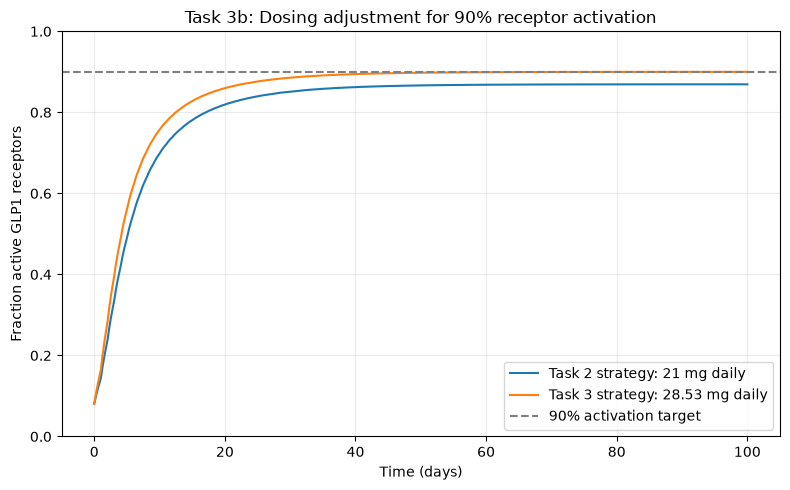

Original daily dose: 21.00 mg
Optimized daily dose: 28.53 mg
Dosing interval: 24 hours
Free concentration at day 100: 0.6851 nM
Average activation during final day: 90.00%
Final-day activation range: 89.99%–90.01%


In [16]:
#Code for part 2
from scipy.optimize import brentq

target_activity = 0.90

def final_day_mean_activity(dose):
    """Average receptor activation during days 99–100."""
    t, c = simulate(0.006, dose, 0.01, 24, 100)
    activity = Fact(c, Kd_cavalitide)

    last_day = t >= 99 * 24

    return trapezoid(
        activity[last_day], t[last_day]
    ) / (t[last_day][-1] - t[last_day][0])

# Find the dose for which final-day average activation equals 90%.
dose_optimized = brentq(
    lambda dose: final_day_mean_activity(dose) - target_activity,
    0,
    210,
    xtol=1e-4
)

# Simulate this dosing strategy from the start of treatment.
t_opt, c_opt = simulate(0.006, dose_optimized, 0.01, 24, 100)
activity_opt = Fact(c_opt, Kd_cavalitide)

# Compare the original and optimized dosing strategies.
plt.figure(figsize=(8, 5))
plt.plot(
    t_base / 24, activity_base,
    label="Task 2 strategy: 21 mg daily"
)
plt.plot(
    t_opt / 24, activity_opt,
    label=f"Task 3 strategy: {dose_optimized:.2f} mg daily"
)
plt.axhline(
    target_activity, color="gray", linestyle="--",
    label="90% activation target"
)
plt.xlabel("Time (days)")
plt.ylabel("Fraction active GLP1 receptors")
plt.title("Task 3b: Dosing adjustment for 90% receptor activation")
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

last_day_opt = t_opt >= 99 * 24

print(f"Original daily dose: 21.00 mg")
print(f"Optimized daily dose: {dose_optimized:.2f} mg")
print(f"Dosing interval: 24 hours")
print(f"Free concentration at day 100: {c_opt[-1]:.4f} nM")
print(
    f"Average activation during final day: "
    f"{final_day_mean_activity(dose_optimized):.2%}"
)
print(
    f"Final-day activation range: "
    f"{activity_opt[last_day_opt].min():.2%}–"
    f"{activity_opt[last_day_opt].max():.2%}"
)

## Task 3 Part 2 Interpretation
While keeping all other parameters constant, we adjusted the daily dose to achieve 90% average receptor activation by day 100. To do this, we used the brentq function which adjusts the dosing between 0 and 210 mg until it finds a dosing which predicts 90% activation. For each proposed dose, the code repeated the simulation and compared the final day average to the target. Once the model found that the optimized dose was 28.53 mg, it was plotted against the original 21 mg daily dosing. Dose interval was left the same at 24 hours.

The increased dose raises free Cavalitide levels from 0.5043 nM to 0.6851 nM leading to the average activation on day 100 to rise from 86.92% to 90.00%. This greater activation could support greater response, but more testing would need to be done to explore clinical outcomes. This model gives a canidate dosage for further investigation and clinical trials.

## Conclusions:

Our study suggests that Cavalitide is a potential alternative medication for obesity․ Task 1 results show that the Kd value for Cavalitide was 0․077 nM‚ which is lower than the Kd value for semaglutide of 0․38 nM‚ suggesting stronger GLP1R binding at lower Cavalitide doses․ Task 2 modeling of Cavalitide as an oral medication found that reducing the daily dose from 25 mg to 21 mg reduced the steady-state unbound plasma concentration from approximately 0․60 nM to 0․50 nM. For Task 3, combining the PK and PD models showed that the 21 mg daily dose produced an average final day receptor activation of 86.92%. Increasing the daily dose to 28.53 mg achieved the 90% activation target while maintaining a 24 hour dosing interval. Task 3 demonstrated how combining the models can guide dosing based on receptor activity rather than blood concentration alone. Findings from this study suggest potential uses for Cavalitide as an oral medication․ Further research is needed to evaluate the relative benefits of Cavalitide compared with oral or injectable semaglutide․

## Limitations and Future Work:

The first limitation of our work was assumptions made about the Cavalitide molecule. We assumed that Cavalitide shared the same properties of semaglutide such as elimination rate, molecular weight, etc.. To perform clinical testing, these properties would need to measured for Cavalitide. We also assumed that natural GLP1 concentrations were constant across patients and that receptor binding immediately produced full activation. It is likely that GLP1 levels vary patient to patient which would cause fluctuations in average final day receptor activation at our optimized dose. Missed doses, changes in receptor responsiveness, and side effects were also not taken into account meaning that the achieved 90% receptor activation may not demonstrate specific amounts of weight loss or establish that the drug is safe.

With more time we would be able to measure Cavalitide's properties and variations within patients to establish a more concrete dosing strategy. Task 2 could be adapted to use Cavalitide's measured pharmacokinetics properties, and Task 3 could test how changes in these properties affect receptor activation and dosage.

Published research reported a semaglutide GLP1 receptor binding affinity of 0.38 nM comapred to Cavalitide's Kd of 0.077 nM. This suggests that Cavalitide binds stronger to receptors than semaglutide if the model is accurate. Future work could compare receptor activation for these two drugs to attempt to validate clinical testing of Cavalitide as a replacement for semaglutide.

## AI Usage Statement:
AI was used to help write code for Tasks 1-3 along with supporting research and finding sources for the Disease Background and Limitations and Future Work sections. For Task 3, AI was specifically used to help write code for graphs, analyze the code, and find the optimized dosing for 90% average receptor activation on the final day.

## GitHub Repository Link:
https://github.com/ahemdhira-arch/BME2315-Module3.git



## References

1. **CDC – Obesity and Severe Obesity Prevalence in Adults**  
   https://www.cdc.gov/nchs/products/databriefs/db508.htm

2. **NIDDK – Treatment for Overweight & Obesity**  
   https://www.niddk.nih.gov/health-information/weight-management/adult-overweight-obesity/treatment

3. **NIDDK – Prescription Medications to Treat Overweight & Obesity**  
   https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity

4. **UVA BME 2315 – Module 3 Project Description (Fall 2026)**  
   Course-provided document: `Module 3 project description(1).pdf`

5. **UVA BME 2315 – Receptor Binding and Pharmacokinetics Code (Fall 2026)**  
   Course-provided files: `ligand_receptor.py`, `GLP1_GLP1R.py`, `fit_semaglutide_GLP1R.py`, `semaglutidePK.py`

6. **UVA BME 2315 – Experimental Binding Data (Fall 2026)**  
   Course-provided datasets: `cavalitide_data.csv`, `semaglutide_data.csv`

7. **OpenAI – ChatGPT (2026)**  
   https://chatgpt.com/  
   Used for assistance with Python code and debugging

8. **ACS Publications**

   https://pubs.acs.org/jmcmar/article-abstract/58/18/7370/1339277/Discovery-of-the-Once-Weekly-Glucagon-Like-Peptide?redirectedFrom=fulltext

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*